# **Tutorial:** Custom YOLO Object Detection with RoboFlow

In this tutorial, you'll learn how to create a custom YOLO object detection model using your own classes and annotations with RoboFlow.

### **Step 1: Install Required Dependencies**

In [1]:
#%pip install --upgrade ultralytics
#%pip install opencv-python
#%pip install roboflow
#%pip install matplotlib
#%pip install numpy==1.26.4 --force-reinstall

### **Step 2: Import Required Libraries**

In [2]:
import cv2
from roboflow import Roboflow
from ultralytics import YOLO
import matplotlib.pyplot as plt
import numpy as np
import os
from IPython.display import Image, display

### **Step 3: Set Up RoboFlow Account**

1. Go to RoboFlow and create a free account
2. Create a new project and select "Object Detection" as project type
3. Choose "YOLOv26" as the model format

### **Step 4: Upload and Annotate Your Images**

#### Using RoboFlow Web Interface:

1. Click "Upload" to add your images
2. Use the annotation tool to draw bounding boxes around objects
3. Assign the correct class labels to each bounding box
4. Apply preprocessing and augmentation as needed

### **Step 5. Download your Custom your Dataset**

1. In RoboFlow, go to your project dashboard
2. Click "Generate" to create a dataset version
3. Apply any desired augmentations
4. Click "Export" and select "YOLOv**x**" format (**x** the version you are using)
5. Copy the download code

In [3]:
from roboflow import Roboflow
rf = Roboflow(api_key="c66Bl2JwDK8KwrNuXSvP")
project = rf.workspace("yesnt").project("objectdetection-6pilj")
version = project.version(1)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to ObjectDetection-1 in yolo26:: 100%|██████████| 356/356 [00:00<00:00, 829.20it/s] 


### **Step 6: Train Your Custom YOLO Model**

In [4]:
OUTPUT_DIR = 'runs/detect/custom_yolo_model'

# Load the YOLO model with custom configuration
model = YOLO('yolo26n.pt')  # Using nano version as base

# Train the model on your custom dataset
results = model.train(
    data=f'{dataset.location}/data.yaml',  # Path to dataset config
    epochs=60,  # Number of training epochs
    imgsz=640,  # Image size
    batch=8,   # Batch size
    name='custom_yolo_model'  # Name for the training run
)
print("Pesos:", model.trainer.best)

Ultralytics 8.4.211  Python-3.11.17 torch-2.15.0+cpu CPU (AMD Ryzen 7 7700X 8-Core Processor)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\mcd\mcd_Fundamentos_AI\mcd_yolo_object_detection\ObjectDetection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=

### **Step 7: Evaluate Your Model**

In [5]:
# Evaluate model performance
metrics = model.val()  # Validate the model
print(f"VALID  mAP50: {metrics.box.map50:.3f} | mAP50-95: {metrics.box.map:.3f}")
for i, c in enumerate(metrics.box.ap_class_index):
    print(f"  {model.names[int(c)]}: AP50={metrics.box.ap50[i]:.3f} | AP50-95={metrics.box.ap[i]:.3f}")

# Show some validation results
test_metrics = model.val(split='test')
print(f"TEST   mAP50: {test_metrics.box.map50:.3f} | mAP50-95: {test_metrics.box.map:.3f}")
print("Gráficos (confusion_matrix, PR, results):", metrics.save_dir)

Ultralytics 8.4.211  Python-3.11.17 torch-2.15.0+cpu CPU (AMD Ryzen 7 7700X 8-Core Processor)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 247.6±32.7 MB/s, size: 43.8 KB)
val: Scanning D:\mcd\mcd_Fundamentos_AI\mcd_yolo_object_detection\ObjectDetection-1\valid\labels.cache... 35 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 35/35  0.0s
WARNING Box and segment counts should be equal, but got len(segments) = 41, len(boxes) = 43. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.8it/s 1.1s0.9s
                   all         35         43      0.958      0.963      0.979       0.76
                  Sabo         25         26          1      0.927       0.98      0

### **Step 8: Test Your Custom Model on an Image**


image 1/1 d:\mcd\mcd_Fundamentos_AI\mcd_yolo_object_detection\datasets\WIN_20261111_20_29_33_Pro.jpg: 384x640 1 TazaStarWars, 43.0ms
Speed: 1.7ms preprocess, 43.0ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)


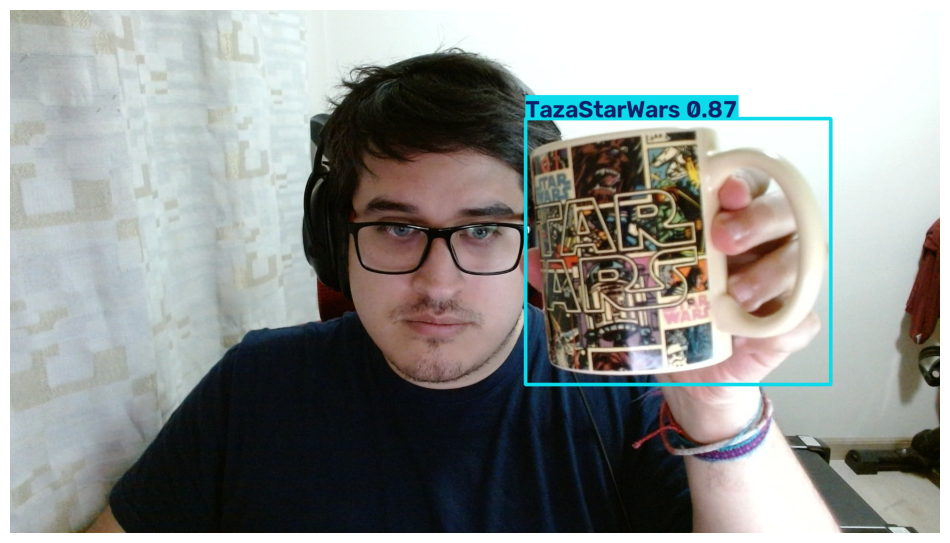

In [7]:
from pathlib import Path

BASE = Path.cwd()   # ...\mcd_yolo_object_detection
WEIGHTS = BASE / 'runs' / 'detect' / 'custom_yolo_model' / 'weights' / 'best.pt'
TEST_IMG = BASE / 'datasets' / 'WIN_20261111_20_29_33_Pro.jpg'
assert WEIGHTS.exists(), WEIGHTS
assert TEST_IMG.exists(), TEST_IMG

# Load your custom trained model
custom_model = YOLO(str(WEIGHTS))

# Test on a sample image
results = custom_model(str(TEST_IMG), conf=0.25)

# Display results
%matplotlib inline
for result in results:
    img = result.plot()
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 8))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.show()

### **Step 9: Test Your Custom Model on Video**

In [9]:
import time

rt_model = YOLO(str(WEIGHTS))

cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
if not cap.isOpened():
    raise RuntimeError("No se pudo abrir la webcam (revisa permisos de cámara o el índice)")

# 3) Bucle de inferencia en tiempo real
t_prev = time.time()
try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        res = rt_model.predict(frame, conf=0.5, imgsz=640, verbose=False)[0]
        vis = res.plot()
        t_now = time.time(); fps = 1.0 / (t_now - t_prev); t_prev = t_now
        cv2.putText(vis, f"FPS: {fps:.1f}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        cv2.imshow("YOLO26 custom - 'q' para salir", vis)
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break
finally:
    # 4) Liberar recursos aunque ocurra un error
    cap.release()
    cv2.destroyAllWindows()
    cv2.waitKey(1)

## **Activity: Create Your Custom Detector**

1. **Create a RoboFlow account** and set up a new project
2. **Upload at least 25 images** of your custom objects (at least 2)
3. **Annotate all images** with bounding boxes and class labels
4. **Train a YOLO model** on your custom dataset
5. **Test your model** on new images and evaluate its performance
6. **Implement real-time detection** with your custom classes

## **Grading Rubric:**

| **Criteria** | **Points** | **Description** |
|-------------|-----------|----------------|
| **1. Dataset Creation** | 4 | Successfully creates and annotates a custom dataset with at least 25 images and multiple classes in RoboFlow. |
| **2. Model Training** | 1 | Properly trains a YOLOv26 model on the custom dataset with appropriate hyperparameters. |
| **3. Model Evaluation** | 1 | Evaluates model performance with appropriate metrics and provides analysis of results. |
| **4. Custom Detection** | 3 | Implements real-time detection with custom classes and displays results correctly. You have to use video from your webcam, no images or saved videos allowed. |
| **5. Documentation** | 1 | Provides clear documentation of the process, including dataset details and model performance. |

**Total: 10 points**

## **Tips for Success:**

- **Quality over quantity**: Well-annotated images are more important than many poorly annotated ones
- **Class balance**: Try to have a similar number of examples for each class
- **Variety**: Include different angles, lighting conditions, and backgrounds
- **Augmentation**: Use RoboFlow's augmentation features to expand your dataset

<p style="text-align: right; font-size:14px; color:gray;">
<b>Prepared by:</b><br>
Manuel Eugenio Morocho-Cayamcela
</p>